# OVCA leave-one-cell-type-out, with a **Path2Space baseline**

This notebook is [`OVCA_03_loo.ipynb`](OVCA_03_loo.ipynb) turned into a **benchmark template**: every
model — the two already here and any future one — is scored against a fixed, external,
state-of-the-art baseline for predicting expression from H&E, **Path2Space**
([Shulman et al.](../data/path2space.pdf); run in
[`gene_expression_prediction.ipynb`](gene_expression_prediction.ipynb)).

Everything about the LOO design — the ROI-level split, the arms, the donor pools, the ceiling, the
ID caveat, the seeds — is inherited unchanged. Read the header of `OVCA_03_loo.ipynb` for it; it is
not repeated here. This header only covers what is new.

## What Path2Space is, and what it is not

- **Model.** CTransPath features (Macenko-normalised tiles, `amp=False`) -> an ensemble of MLPs
  with a ReLU output -> 14,068 genes. Trained on **25 Visium slides from 15 triple-negative breast
  cancer patients**, 55 um spots. Ovarian tissue is out of its training domain.
- **Output units.** Paper Methods: *"gene expression values were incremented by 1 and
  log10-transformed"* — i.e. the target was `log10(raw UMI + 1)` per spot, with no library-size
  normalisation. So `10**pred - 1` recovers **pseudo-UMI counts**, which is what goes into the
  scoring pipeline (whose own CPM step then removes the spot-vs-cell depth difference).
- **It is a *direct* model, not a counterfactual.** It has no cell-type input and no domain input:
  pixels in, expression out. It cannot be told "you are now in Tumor". So its row is the **2,244
  real Tumor cells in the withheld ROIs 3/6/8/9, each predicted from its own tile** — the same
  question the `embeddings (own tile)` ceiling answers, and it sits next to that row with
  `kind = "direct"`. It is **not** a peer of the counterfactual rows: those predict the held-out
  Stromal cells without ever seeing their tissue; Path2Space reads it.
- **No leakage question.** Path2Space was never trained on OVCA, so the ROI split does not apply to
  it. It is deterministic and untrained here -> **one run, no seeds** (`sd` shown as `—`).
- **Remaining handicap, accepted on purpose.** Visium poly-A capture and Xenium probe efficiency
  differ gene by gene, so Path2Space's absolute levels carry a per-gene platform offset that
  `observed_control` scoring counts as error. That *is* what "off-the-shelf SOTA applied to Xenium"
  means; section D checks separately that the pipeline itself is sound.

## Gene universes — two tables

Path2Space predicts **3,603 of the 5,090** post-QC panel genes. `compare_adatas` CPM-normalises
over, and picks its top-50 DE genes from, whatever genes it is given, so rows scored on different
gene sets are not comparable. Hence:

| table | genes | rows | purpose |
|---|---|---|---|
| **C1** | full panel, 5,090 | labels + embeddings (no Path2Space) | continuity: must reproduce `OVCA_03_loo` exactly |
| **C2** | shared with Path2Space, 3,603 | **all rows re-scored** + Path2Space | **the baseline comparison — score future models here** |

The C2 gene list is written to `shared_genes_path2space.txt`. Restricting to it drops **MYH11**,
C7 and ADAMTS14 from the OOD top-50 (MYH11 is *the* smooth-muscle marker), so C2's top-50 is a
slightly different gene set from C1's.

## Section D is a Path2Space sanity check only

Section D scores Path2Space the way its authors do (per-gene Pearson across locations after spatial
smoothing, "robust" = r > 0.4). It exists to tell a genuinely weak baseline apart from a broken
pipeline. It is **not** a model comparison; `embeddings (own tile)` appears there only as a
reference line.

## How to run

1. **Path2Space predictions** must exist at `data/ovca_path2space/ovca_path2space_predictions.h5ad`.
   They do (17,278 cells x 14,068 genes, covering all 14,170 LOO cells). If that file is ever
   missing, run [`gene_expression_prediction.ipynb`](gene_expression_prediction.ipynb) top to
   bottom in the **`lazyslide-env`** kernel **on a GPU node** — it cannot run here (needs
   torchstain + CTransPath + the 1.76B-parameter ensemble). Section A stops with this message if
   the file is absent.
2. Run this notebook in the **`cellina_edge`** kernel. `RETRAIN = False` (default) skips section B
   and reads the cached labels/embeddings predictions; set it to `True` to retrain all 3 seeds.

All predictions, models and metric tables live in one model-neutral directory,
**`/scratch/spiljak/wsi_ood_preds/ovca_loo/`** (formerly `ovca_labels_vs_embed/`, which is kept as a
symlink so `OVCA_03_loo.ipynb` still runs). **Adding a model** = write
`{key}_seed{s}.h5ad` there (same layout as `save_pred` produces) and add one line to `MODELS`.

## A. Setup — data, split, arms, donor pools, Path2Space  *(`cellina_edge` kernel)*

In [1]:
import os
import sys

import numpy as np
import pandas as pd

# ../scripts for the LOO plumbing (eval/metrics); ../src for the `wsi` package (LabelsBaseline,
# EmbeddingsBaseline), which is not pip-installed into cellina_edge.
# Resolved from PROJECT_ROOT rather than a relative "../" path: kernel cwd is not reliably the
# notebook's own directory when connecting to an existing Jupyter server (e.g. from VS Code).
PROJECT_ROOT = "/g/stegle/spiljak/projects/main_wsi_ood"
sys.path.append(os.path.join(PROJECT_ROOT, "scripts"))
sys.path.append(os.path.join(PROJECT_ROOT, "src"))

from utils import set_seed
from eval import (
    load_ovca_loo_bundle,
    preprocess_ovca,
    split_indices_roi_holdout,   # ROI-level: the only leakage-safe split for tile-conditioned models
    make_comparison_adata,
    run_loo_eval,
    COUNTS_PER_K,
)
from configs.adata_ovca_config import ADATA_ARGS
from configs.embeddings_config import EMBEDDING_KEY, SCALED_EMBEDDING_KEY, SEEDS

# False -> skip section B and score the cached predictions. True -> retrain labels + embeddings
# for every seed (overwrites the cached models and predictions).
RETRAIN = False

# --- experiment config (see configs/adata_ovca_config.py) -------------------
BUNDLE_DIR = os.path.join(PROJECT_ROOT, "data/ovca_loo")
P2S_H5AD = os.path.join(PROJECT_ROOT, "data/ovca_path2space/ovca_path2space_predictions.h5ad")

LABELS_KEY = ADATA_ARGS["labels_key"]             # "cell_type"     always ground truth
DOMAINS_KEY = ADATA_ARGS["domains_key"]           # "domain"        ground truth throughout
HOLDOUT_CT = ADATA_ARGS["holdout_celltype"]       # "Stromal"
CONTROL_LABEL = ADATA_ARGS["control_domains"][0]  # "Smooth muscle" (quiescent stroma)
HOLDOUT_LABEL = ADATA_ARGS["holdout_domains"][0]  # "Tumor"
HOLDOUT_ROIS = ADATA_ARGS["holdout_rois"]         # [9, 6, 3, 8] -- whole Tumor ROIs withheld

PERT_COL = "domain_arm"   # 2-level arm label on the comparison AnnDatas

# One model-neutral directory for every model's predictions (on /scratch: /g/stegle is ~full).
PRED_DIR = "/scratch/spiljak/wsi_ood_preds/ovca_loo"
MODEL_DIR = os.path.join(PRED_DIR, "models")
os.makedirs(MODEL_DIR, exist_ok=True)

# Registry of what section C scores: key -> (display name, kind, seeds).
# `kind` travels with the numbers so a direct row can never be mistaken for a counterfactual peer.
# seeds=None marks a deterministic model stored as `{key}.h5ad` (no seed suffix).
# To add a model: write its predictions to PRED_DIR and add ONE line here.
MODELS = {
    "labels":          ("labels",                              "counterfactual",     SEEDS),
    "emb_seen_8ROIs":  ("embeddings (donor: other 8 ROIs)",    "counterfactual",     SEEDS),
    "emb_unseen_ROIs": ("embeddings (donor: ROIs 3/6/8/9)",    "counterfactual",     SEEDS),
    "emb_ceiling":     ("embeddings (own tile)",               "direct - CEILING",   SEEDS),
    "path2space":      ("Path2Space (CTransPath, own tile)",   "direct - BASELINE",  None),
}

print(f"{CONTROL_LABEL!r} -> {HOLDOUT_LABEL!r}, holding out {HOLDOUT_CT!r}")
print(f"withheld ROIs: {HOLDOUT_ROIS}   seeds: {SEEDS}   RETRAIN={RETRAIN}   ->  {PRED_DIR}")

'Smooth muscle' -> 'Tumor', holding out 'Stromal'
withheld ROIs: [9, 6, 3, 8]   seeds: [0, 1, 2]   RETRAIN=False   ->  /scratch/spiljak/wsi_ood_preds/ovca_loo


In [2]:
# Load the prepared bundle (raw counts + micron centroids + uni2/virchow2 per-cell H&E
# embeddings), then the shared QC. n_top_genes=None: the Xenium panel is already curated, so no
# HVG subsetting. No spatial-feature step -- cellina is gone and neither model uses the graph.
adata = load_ovca_loo_bundle(BUNDLE_DIR)
adata = preprocess_ovca(
    adata,
    n_top_genes=ADATA_ARGS["n_top_genes"],
    labels_key=LABELS_KEY,
    domains_key=DOMAINS_KEY,
    pred_domains_key=ADATA_ARGS["pred_domains_key"],  # carried as a column, never used
)
print(adata)
print(f"\n{EMBEDDING_KEY}: {adata.obsm[EMBEDDING_KEY].shape}")

# Expect 14170 x 5090 (filter_genes drops 11 of the 5101; no cells dropped), virchow2 (14170, 2560)

/g/stegle/spiljak/projects/main_wsi_ood/scripts/eval.py:71: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs[labels_key] = adata.obs[labels_key].astype("category")


AnnData object with n_obs × n_vars = 14170 × 5090
    obs: 'cell_id', 'cell_type', 'domain', 'pred_domain', 'roi_id', 'roi_domain', 'split_05', 'n_counts'
    var: 'n_counts'
    obsm: 'spatial', 'uni2', 'virchow2'
    layers: 'counts'

virchow2: (14170, 2560)


In [3]:
# ROI-level leave-one-cell-type-out split: withhold all cells in Tumor ROIs [9,6,3,8] AND every
# (Stromal, Tumor) cell slide-wide. Sets obs["is_scored_target"] = the Tumor cells inside those
# ROIs, which is what section C scores.
train_idx, val_idx, test_idx = split_indices_roi_holdout(
    adata, HOLDOUT_CT, HOLDOUT_ROIS,
    labels_key=LABELS_KEY, domains_key=DOMAINS_KEY,
    holdout_domains=ADATA_ARGS["holdout_domains"], seed=0,
)
print(f"train={len(train_idx)}  val={len(val_idx)}  test={len(test_idx)}")
print(f"scored target cells: {int(adata.obs['is_scored_target'].sum())}")

# Expect train=10408  val=1156  test=2606   scored target=2244

train=10408  val=1156  test=2606
scored target cells: 2244


In [4]:
# Scale the H&E embedding (only needed to TRAIN the embeddings model, i.e. when RETRAIN).
# DecoderSCVI's first layer is a plain Linear and Virchow2's per-feature std spans 0.027 to 16, so
# unscaled features would enter with a 600x scale spread. The scaler is fit on TRAINING CELLS
# ONLY, so the withheld ROIs do not even influence the standardisation.
from joblib import dump
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(np.asarray(adata.obsm[EMBEDDING_KEY])[train_idx])
adata.obsm[SCALED_EMBEDDING_KEY] = np.ascontiguousarray(
    scaler.transform(np.asarray(adata.obsm[EMBEDDING_KEY])).astype(np.float32)
)
if RETRAIN:
    dump(scaler, os.path.join(MODEL_DIR, f"{EMBEDDING_KEY}_scaler.joblib"))

x = adata.obsm[SCALED_EMBEDDING_KEY]
print(f"{SCALED_EMBEDDING_KEY}: {x.shape}  mean={x.mean():.3f}  std={x.std():.3f}  "
      f"(fit on {len(train_idx)} training cells)")

virchow2_scaled: (14170, 2560)  mean=-0.000  std=0.994  (fit on 10408 training cells)


In [5]:
# --- Arms -------------------------------------------------------------------------------------
# control = ALL Smooth-muscle cells (inputs to the counterfactual, deliberately kept in training)
# target  = the Tumor cells inside the withheld ROIs (never seen: not their expression, not their
#           pixels). Their measured counts are what every prediction is scored against.
mask_control = (adata.obs[DOMAINS_KEY].astype(str) == CONTROL_LABEL).values
mask_target = adata.obs["is_scored_target"].values
idx_control = np.where(mask_control)[0]
idx_target = np.where(mask_target)[0]

# Cell type per arm, attached to every comparison AnnData so section C can slice OOD from ID.
# The counterfactual moves control cells into Tumor but each keeps its own type, so a predicted
# counterfactual arm carries the CONTROL cells' types.
ct_control = adata.obs[LABELS_KEY].astype(str).values[mask_control]
ct_target = adata.obs[LABELS_KEY].astype(str).values[mask_target]

# --- Donor pools for the embeddings counterfactual ---------------------------------------------
# A donor lends its Virchow2 vector and nothing else. Stromal is excluded from BOTH pools so the
# held-out cell type never re-enters. See the header for what each pool tests.
is_tumor = (adata.obs[DOMAINS_KEY].astype(str) == HOLDOUT_LABEL).values
is_holdout_ct = (adata.obs[LABELS_KEY].astype(str) == HOLDOUT_CT).values
in_holdout_roi = adata.obs["roi_id"].isin(HOLDOUT_ROIS).values

DONOR_POOLS = {
    "emb_seen_8ROIs": np.where(is_tumor & ~in_holdout_roi & ~is_holdout_ct)[0],
    "emb_unseen_ROIs": np.where(is_tumor & in_holdout_roi & ~is_holdout_ct)[0],
}

print(f"control({CONTROL_LABEL}) = {idx_control.size}    target({HOLDOUT_LABEL}, withheld ROIs) = {idx_target.size}")
for name, pool in DONOR_POOLS.items():
    print(f"  donor pool {name:11s} = {pool.size:5d} cells   (Stromal excluded)")

print("\ncell types, predicted arm (control) vs observed target arm:")
print(pd.concat(
    {"predicted (control cells)": pd.Series(ct_control).value_counts(),
     "observed (target cells)": pd.Series(ct_target).value_counts()},
    axis=1,
).fillna(0).astype(int).to_string())
print("\n^ the ID regime compares the non-Stromal rows of these two columns against each other;")
print("  see the composition caveat in the header before reading the ID numbers.")

control(Smooth muscle) = 2803    target(Tumor, withheld ROIs) = 2244
  donor pool emb_seen_8ROIs =  5411 cells   (Stromal excluded)
  donor pool emb_unseen_ROIs =  1684 cells   (Stromal excluded)

cell types, predicted arm (control) vs observed target arm:
             predicted (control cells)  observed (target cells)
Stromal                           2538                      560
Endothelial                        179                       59
Malignant                           42                     1346
Myeloid                             28                      125
Lymphoid                            16                       42
Pericytes                            0                      108
Epithelial                           0                        4

^ the ID regime compares the non-Stromal rows of these two columns against each other;
  see the composition caveat in the header before reading the ID numbers.


In [6]:
# Observed pair (ground truth): real control counts vs real target counts, with the cell-type
# label attached so section C can slice OOD (held-out type) from ID (held-in types).
import anndata as ad
if hasattr(ad, "settings"):  # anndata >= 0.11 only; cellina_edge has 0.10
    ad.settings.allow_write_nullable_strings = True

observed = make_comparison_adata(
    adata.layers["counts"][mask_control, :],
    adata.layers["counts"][mask_target, :],
    adata.var_names, control_label=CONTROL_LABEL, perturbed_label=HOLDOUT_LABEL,
    pert_col=PERT_COL,
)
observed.obs[LABELS_KEY] = np.concatenate([ct_control, ct_target])
observed.write(os.path.join(PRED_DIR, "observed.h5ad"))
observed

# Expect 5047 x 5090  (2803 control + 2244 target)

AnnData object with n_obs × n_vars = 5047 × 5090
    obs: 'domain_arm', 'cell_type'

### Path2Space predictions -> a scoreable AnnData

Loaded straight from the h5ad written by `gene_expression_prediction.ipynb`, with **`h5py`, not
anndata**: that file was written by anndata 0.12 (`lazyslide-env`) with Arrow-backed string
columns, which `cellina_edge`'s anndata 0.10 cannot read — the same reason the LOO data comes as a
plain bundle. Rows are matched to `adata` by `cell_id`, genes by name.

Arms, in the same layout as every other prediction file:

- **perturbed arm** = Path2Space on the 2,244 scored Tumor cells' own tiles (this is the row);
- **control arm** = Path2Space on the 2,803 Smooth-muscle cells' own tiles. Not read by the
  `observed_control` tables — only by the figure, for symmetry with the other files.

Values are converted `10**x - 1` from the model's `log10(UMI + 1)` scale back to pseudo-counts.

In [7]:
import h5py

if not os.path.exists(P2S_H5AD):
    raise FileNotFoundError(
        f"{P2S_H5AD} is missing. Run notebooks/gene_expression_prediction.ipynb top to bottom in "
        "the lazyslide-env kernel on a GPU node, then re-run this notebook."
    )

with h5py.File(P2S_H5AD, "r") as f:
    p2s_cells = f["obs/cell_id/values"].asstr()[:]
    p2s_genes = f["var/gene/values"].asstr()[:]
    p2s_X = f["X"][:]                          # (17278, 14068) float32, ~1 GB, log10(UMI+1) scale

# Genes: Xenium panel (post-QC) order, restricted to what Path2Space predicts.
p2s_gene_pos = pd.Series(np.arange(len(p2s_genes)), index=p2s_genes)
SHARED_GENES = [g for g in adata.var_names if g in p2s_gene_pos.index]
with open(os.path.join(PRED_DIR, "shared_genes_path2space.txt"), "w") as fh:
    fh.write("\n".join(SHARED_GENES) + "\n")

# Cells: every LOO cell must be present (the 17,278-cell ROI population is a superset).
p2s_cell_pos = pd.Series(np.arange(len(p2s_cells)), index=p2s_cells)
missing = adata.obs_names.difference(p2s_cell_pos.index)
assert len(missing) == 0, f"{len(missing)} LOO cells have no Path2Space prediction"
rows = p2s_cell_pos.loc[adata.obs_names].to_numpy()

# (n_LOO_cells, n_shared_genes) on the model's native log10(UMI+1) scale -- section D uses this.
p2s_log10 = p2s_X[np.ix_(rows, p2s_gene_pos.loc[SHARED_GENES].to_numpy())]
del p2s_X

p2s_counts = np.power(10.0, p2s_log10, dtype=np.float32) - 1.0
p2s_pred = make_comparison_adata(
    p2s_counts[mask_control], p2s_counts[mask_target], SHARED_GENES,
    control_label=CONTROL_LABEL, perturbed_label=HOLDOUT_LABEL, pert_col=PERT_COL,
)
# Direct model: the perturbed arm IS the target cells, so it carries their cell types.
p2s_pred.obs[LABELS_KEY] = np.concatenate([ct_control, ct_target])
p2s_pred.write(os.path.join(PRED_DIR, "path2space.h5ad"))

print(f"shared genes: {len(SHARED_GENES)} / {adata.n_vars}   -> shared_genes_path2space.txt")
print(f"path2space.h5ad: {p2s_pred.shape}   pseudo-count range "
      f"[{p2s_counts.min():.3g}, {p2s_counts.max():.3g}]")
assert (p2s_pred.X.sum(1) > 0).all(), "a cell has zero total pseudo-counts -> CPM would divide by 0"

# Expect shared genes: 3603 / 5090,  path2space.h5ad: (5047, 3603)

shared genes: 3603 / 5090   -> shared_genes_path2space.txt
path2space.h5ad: (5047, 3603)   pseudo-count range [0, 47.4]


## B. Train labels + embeddings, 3 seeds  *(skipped unless `RETRAIN = True`)*

Identical to section B of `OVCA_03_loo.ipynb`. Per seed: train `LabelsBaseline`, run its
counterfactual, then train `EmbeddingsBaseline` and run its three inference passes (two donor pools
+ the own-tile ceiling). The embeddings model is trained **once** per seed — the two donor rows are
the same network queried with different conditioning vectors.

Order matters inside the loop: `setup_anndata` re-registers the shared `adata`, so all inference
for one model is finished before the next one is set up. Path2Space needs no training here.

In [8]:
import scvi
from wsi.labels_baseline import LabelsBaseline
from wsi.embeddings_baseline import EmbeddingsBaseline
from configs.labels_config import (
    MODEL_ARGS as LABELS_MODEL_ARGS,
    TRAIN_ARGS as LABELS_TRAIN_ARGS,
    PLAN_KWARGS as LABELS_PLAN_KWARGS,
)
from configs.embeddings_config import (
    MODEL_ARGS as EMB_MODEL_ARGS,
    TRAIN_ARGS as EMB_TRAIN_ARGS,
    PLAN_KWARGS as EMB_PLAN_KWARGS,
)


def _train_args(base):
    """Same split for every model, every seed."""
    a = dict(base)
    a["datasplitter_kwargs"] = {"external_indexing": [train_idx, val_idx, test_idx]}
    return a


def save_pred(key, seed, control_arm, perturbed_arm, ct_perturbed):
    """Write a model's (control reconstruction, prediction) pair as a scoreable AnnData."""
    pred = make_comparison_adata(
        control_arm, perturbed_arm, adata.var_names,
        control_label=CONTROL_LABEL, perturbed_label=HOLDOUT_LABEL, pert_col=PERT_COL,
    )
    pred.obs[LABELS_KEY] = np.concatenate([ct_control, ct_perturbed])
    path = os.path.join(PRED_DIR, f"{key}_seed{seed}.h5ad")
    pred.write(path)
    print(f"    -> {os.path.basename(path)}  {pred.shape}")
    return pred


if not RETRAIN:
    print("RETRAIN=False -> using cached predictions in", PRED_DIR)
else:
    for seed in SEEDS:
        print(f"\n{'=' * 70}\nSEED {seed}\n{'=' * 70}")
        set_seed(seed)
        scvi.settings.seed = seed

        # ---------- labels baseline: domain as a 5-way one-hot ------------------------------------
        LabelsBaseline.setup_anndata(
            adata, labels_key=LABELS_KEY, domains_key=DOMAINS_KEY,
            batch_key=ADATA_ARGS["batch_key"], layer="counts",
        )
        labels_model = LabelsBaseline(adata, **LABELS_MODEL_ARGS)
        labels_model.train(**_train_args(LABELS_TRAIN_ARGS), plan_kwargs=LABELS_PLAN_KWARGS)
        labels_model.save(os.path.join(MODEL_DIR, f"labels_seed{seed}"), overwrite=True)

        # counterfactual = relabel the control cells' domain to Tumor and decode
        labels_ctrl = labels_model.get_normalized_expression(
            adata[mask_control], library_size=COUNTS_PER_K, batch_size=2048,
        )
        labels_cf = labels_model.get_counterfactual_expression(
            idx_control, target_domain=HOLDOUT_LABEL, batch_size=2048,
        )
        save_pred("labels", seed, labels_ctrl, labels_cf, ct_control)

        # ---------- embeddings baseline: domain as a 2560-d Virchow2 vector ------------------------
        EmbeddingsBaseline.setup_anndata(
            adata, labels_key=LABELS_KEY, embedding_obsm_key=SCALED_EMBEDDING_KEY,
            batch_key=ADATA_ARGS["batch_key"], layer="counts",
        )
        emb_model = EmbeddingsBaseline(adata, **EMB_MODEL_ARGS)
        emb_model.train(**_train_args(EMB_TRAIN_ARGS), plan_kwargs=EMB_PLAN_KWARGS)
        emb_model.save(os.path.join(MODEL_DIR, f"embeddings_seed{seed}"), overwrite=True)

        # control reconstruction: each control cell decoded from its OWN tile
        emb_ctrl = emb_model.get_normalized_expression(
            adata[mask_control], library_size=COUNTS_PER_K, batch_size=2048,
        )

        # counterfactual = hand each control cell a real Tumor cell's H&E vector. One draw per seed,
        # with replacement; the donor indices are persisted so any row can be reproduced exactly.
        rng = np.random.default_rng(seed)
        for key, pool in DONOR_POOLS.items():
            donors = rng.choice(pool, size=idx_control.size, replace=True)
            np.save(os.path.join(PRED_DIR, f"donors_{key}_seed{seed}.npy"), donors)
            emb_cf = emb_model.get_counterfactual_expression(
                idx_control, donor_indices=donors, batch_size=2048,
            )
            save_pred(key, seed, emb_ctrl, emb_cf, ct_control)

        # CEILING (not a counterfactual): each real target cell decoded from its OWN tile and type.
        # The perturbed arm is therefore the target cells, so it carries ct_target.
        emb_direct = emb_model.get_normalized_expression(
            adata[mask_target], library_size="latent", batch_size=2048,
        )
        save_pred("emb_ceiling", seed, emb_ctrl, emb_direct, ct_target)

    print("\nall seeds done")

RETRAIN=False -> using cached predictions in /scratch/spiljak/wsi_ood_preds/ovca_loo


## C. Compare — OOD + ID, mean ± sd over seeds

Each cached prediction is scored with `compare_adatas` on the top-50 observed-effect genes, sliced
by cell type into the two regimes (see `OVCA_03_loo` for why ID must be read with care).
`predicted_logfc_baseline="observed_control"` for **every** row: observed and predicted logFC are
both measured against the same *observed* Smooth-muscle population, so the predicted control arm
is not read by these tables.

Metrics: `pearson_logfc`, `spearman_avg`, `precision_at_top_n` higher-is-better; `rmse_logfc`,
`edistance_pca` lower-is-better. Path2Space has one run, so its `sd` is `—`.

This section re-declares what it needs, so it runs standalone in a fresh kernel.

In [9]:
import os, sys
import numpy as np
import pandas as pd
import scanpy as sc

sys.path.append("/g/stegle/spiljak/projects/main_wsi_ood/scripts")
from eval import run_loo_eval
from metrics import get_perturbation_effects

# Re-declared so section C runs standalone in a fresh kernel.
PRED_DIR = "/scratch/spiljak/wsi_ood_preds/ovca_loo"
PERT_COL, LABELS_KEY = "domain_arm", "cell_type"
CONTROL_LABEL, HOLDOUT_LABEL, HOLDOUT_CT = "Smooth muscle", "Tumor", "Stromal"
SEEDS = [0, 1, 2]
MODELS = {
    "labels":          ("labels",                              "counterfactual",     SEEDS),
    "emb_seen_8ROIs":  ("embeddings (donor: other 8 ROIs)",    "counterfactual",     SEEDS),
    "emb_unseen_ROIs": ("embeddings (donor: ROIs 3/6/8/9)",    "counterfactual",     SEEDS),
    "emb_ceiling":     ("embeddings (own tile)",               "direct - CEILING",   SEEDS),
    "path2space":      ("Path2Space (CTransPath, own tile)",   "direct - BASELINE",  None),
}
REGIMES = {
    "OOD": lambda a: (a.obs[LABELS_KEY].astype(str) == HOLDOUT_CT).values,
    "ID": lambda a: (a.obs[LABELS_KEY].astype(str) != HOLDOUT_CT).values,
}
METRICS = ["pearson_logfc", "rmse_logfc", "spearman_avg", "precision_at_top_n", "edistance_pca"]



def read_h5ad_compat(path):
    """sc.read, falling back to h5py for files written by anndata >= 0.11.

    Predictions from the 2026-08-02 OVCA_03_loo run were written under a newer anndata that
    stores string indices as `nullable-string-array`, which cellina_edge's anndata 0.10 cannot
    decode. These comparison files are simple (dense X + categorical obs + a var index), so they
    are rebuilt by hand in that case.
    """
    import anndata as ad
    import h5py
    try:
        return sc.read(path)
    except Exception as err:
        if "nullable-string-array" not in str(err):
            raise

    def _strings(g):
        return (g["values"] if isinstance(g, h5py.Group) else g).asstr()[:]

    def _column(g):
        if isinstance(g, h5py.Group) and "codes" in g:
            return pd.Categorical.from_codes(g["codes"][:], _strings(g["categories"]))
        if isinstance(g, h5py.Group):
            return _strings(g)
        return g.asstr()[:] if g.dtype.kind in "OS" else g[:]

    with h5py.File(path, "r") as f:
        obs_g, var_g = f["obs"], f["var"]
        obs = pd.DataFrame({c: _column(obs_g[c]) for c in obs_g.attrs.get("column-order", [])
                            if c in obs_g},
                           index=_column(obs_g[obs_g.attrs["_index"]]))
        a = ad.AnnData(X=f["X"][:], obs=obs)
        a.var_names = _column(var_g[var_g.attrs["_index"]])
    return a


observed = read_h5ad_compat(os.path.join(PRED_DIR, "observed.h5ad"))
SHARED_GENES = open(os.path.join(PRED_DIR, "shared_genes_path2space.txt")).read().split()


def load_pred(key, seed):
    name = f"{key}.h5ad" if seed is None else f"{key}_seed{seed}.h5ad"
    return read_h5ad_compat(os.path.join(PRED_DIR, name))


def score(model_keys, genes):
    """Per-(regime, model, seed) metrics, with observed AND predictions restricted to `genes`.

    Subsetting explicitly (rather than relying on compare_adatas' own gene alignment) keeps the
    CPM denominator and the top-50 gene pool identical for every row of one table.
    """
    obs_g = observed[:, genes]
    rows = []
    for key in model_keys:
        display, kind, seeds = MODELS[key]
        for seed in (seeds if seeds is not None else [None]):
            pred = load_pred(key, seed)
            missing = pd.Index(genes).difference(pred.var_names)
            assert len(missing) == 0, f"{key}: {len(missing)} genes missing from predictions"
            pred = pred[:, genes]
            for regime, mask_fn in REGIMES.items():
                o = obs_g[mask_fn(obs_g)].copy()
                p = pred[mask_fn(pred)].copy()
                r = run_loo_eval(o, p, pert_col=PERT_COL, control_label=CONTROL_LABEL).iloc[0]
                rows.append({"regime": regime, "model": display, "kind": kind,
                             "seed": -1 if seed is None else seed,
                             "n_observed": int((o.obs[PERT_COL] != CONTROL_LABEL).sum()),
                             **r.to_dict()})
    return pd.DataFrame(rows)


def summarise(per_seed, model_keys):
    """mean ± sd over seeds; single-run models show '—' for sd."""
    order = [MODELS[k][0] for k in model_keys]
    agg = per_seed.copy()
    agg["regime"] = pd.Categorical(agg["regime"], ["OOD", "ID"], ordered=True)
    agg["model"] = pd.Categorical(agg["model"], order, ordered=True)
    stats = agg.groupby(["regime", "model", "kind"], observed=True)[METRICS].agg(["mean", "std"])
    fmt = lambda m, s: f"{m:.3f} ± —" if pd.isna(s) else f"{m:.3f} ± {s:.3f}"
    table = pd.DataFrame(
        {m: [fmt(a, b) for a, b in zip(stats[(m, "mean")], stats[(m, "std")])] for m in METRICS},
        index=stats.index,
    ).sort_index()
    return table, stats.xs("mean", axis=1, level=1).sort_index()


print(f"observed: {observed.shape}   shared genes: {len(SHARED_GENES)}")

observed: (5047, 5090)   shared genes: 3603


---
### Table C1 — all models on the FULL Xenium panel (5,090 genes) — *no Path2Space*

Continuity table. These numbers must match section C of `OVCA_03_loo.ipynb` exactly; if they do
not, the port (or a cached file) is broken.

In [10]:
C1_KEYS = [k for k in MODELS if k != "path2space"]
per_seed_c1 = score(C1_KEYS, list(observed.var_names))
table_c1, means_c1 = summarise(per_seed_c1, C1_KEYS)

per_seed_c1.to_csv(os.path.join(PRED_DIR, "metrics_C1_fullpanel_per_seed.csv"), index=False)
table_c1.to_csv(os.path.join(PRED_DIR, "metrics_C1_fullpanel_summary.csv"))
means_c1.to_csv(os.path.join(PRED_DIR, "metrics_C1_fullpanel_summary_mean.csv"))

# Regression check against the committed OVCA_03_loo table (same scoring, same files).
prev = pd.read_csv(os.path.join(PRED_DIR, "metrics_summary_mean.csv"), index_col=[0, 1, 2])
cur = means_c1.reset_index().set_index(["regime", "model", "kind"])
common = prev.index.intersection(cur.index)
max_diff = (prev.loc[common, METRICS] - cur.loc[common, METRICS]).abs().to_numpy().max()
print(f"max |diff| vs OVCA_03_loo metrics_summary_mean.csv over {len(common)} rows: {max_diff:.2e}")

print("\nTABLE C1 — FULL PANEL (5,090 genes), no Path2Space")
table_c1

max |diff| vs OVCA_03_loo metrics_summary_mean.csv over 8 rows: 8.50e-10

TABLE C1 — FULL PANEL (5,090 genes), no Path2Space


pearson_logfc  \
regime model                            kind                              
OOD    labels                           counterfactual    0.807 ± 0.056   
       embeddings (donor: other 8 ROIs) counterfactual    0.632 ± 0.019   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    0.698 ± 0.035   
       embeddings (own tile)            direct - CEILING  0.780 ± 0.048   
ID     labels                           counterfactual    0.571 ± 0.027   
       embeddings (donor: other 8 ROIs) counterfactual    0.941 ± 0.005   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    0.929 ± 0.005   
       embeddings (own tile)            direct - CEILING  0.952 ± 0.002   

                                                             rmse_logfc  \
regime model                            kind                              
OOD    labels                           counterfactual    1.041 ± 0.119   
       embeddings (donor: other 8 ROIs) counterfactual    1.344 ± 0.053   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    1.162 ± 0.081   
       embeddings (own tile)            direct - CEILING  1.020 ± 0.071   
ID     labels                           counterfactual    0.768 ± 0.005   
       embeddings (donor: other 8 ROIs) counterfactual    0.943 ± 0.031   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    0.882 ± 0.022   
       embeddings (own tile)            direct - CEILING  0.985 ± 0.036   

                                                           spearman_avg  \
regime model                            kind                              
OOD    labels                           counterfactual    0.510 ± 0.116   
       embeddings (donor: other 8 ROIs) counterfactual    0.342 ± 0.015   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    0.399 ± 0.044   
       embeddings (own tile)            direct - CEILING  0.519 ± 0.060   
ID     labels                           counterfactual    0.661 ± 0.025   
       embeddings (donor: other 8 ROIs) counterfactual    0.922 ± 0.022   
       embeddings (donor: ROIs 3/6/8/9) counterfactual    0.888 ± 0.034   
       embeddings (own tile)            direct - CEILING  0.947 ± 0.017   

                                                         precision_at_top_n  \
regime model                            kind                                  
OOD    labels                           counterfactual        0.427 ± 0.050   
       embeddings (donor: other 8 ROIs) counterfactual        0.240 ± 0.020   
       embeddings (donor: ROIs 3/6/8/9) counterfactual        0.280 ± 0.020   
       embeddings (own tile)            direct - CEILING      0.407 ± 0.061   
ID     labels                           counterfactual        0.473 ± 0.012   
       embeddings (donor: other 8 ROIs) counterfactual        0.773 ± 0.042   
       embeddings (donor: ROIs 3/6/8/9) counterfactual        0.693 ± 0.061   
       embeddings (own tile)            direct - CEILING      0.773 ± 0.042   

                                                           edistance_pca  
regime model                            kind                              
OOD    labels                           counterfactual    11.573 ± 0.833  
       embeddings (donor: other 8 ROIs) counterfactual    11.373 ± 0.434  
       embeddings (donor: ROIs 3/6/8/9) counterfactual     9.160 ± 0.807  
       embeddings (own tile)            direct - CEILING   8.261 ± 0.502  
ID     labels                           counterfactual     6.694 ± 0.033  
       embeddings (donor: other 8 ROIs) counterfactual     7.604 ± 0.133  
       embeddings (donor: ROIs 3/6/8/9) counterfactual     7.038 ± 0.074  
       embeddings (own tile)            direct - CEILING   7.561 ± 0.289

---
### Table C2 — all models + **Path2Space baseline** on the SHARED genes (3,603) — *the benchmark table*

Every row re-scored on the 3,603 genes Path2Space predicts. **This is the table every current and
future model is compared in.** Compare Path2Space with the **`embeddings (own tile)`** row: both are
direct, own-tile H&E -> expression predictions of the same 2,244 cells. The counterfactual rows
answer a harder question (they never see the scored tissue) and are shown for context, not as
Path2Space's peers.

In [11]:
C2_KEYS = list(MODELS)
per_seed_c2 = score(C2_KEYS, SHARED_GENES)
table_c2, means_c2 = summarise(per_seed_c2, C2_KEYS)

per_seed_c2.to_csv(os.path.join(PRED_DIR, "metrics_C2_sharedgenes_per_seed.csv"), index=False)
table_c2.to_csv(os.path.join(PRED_DIR, "metrics_C2_sharedgenes_summary.csv"))
means_c2.to_csv(os.path.join(PRED_DIR, "metrics_C2_sharedgenes_summary_mean.csv"))

print("TABLE C2 — SHARED GENES (3,603), all models + Path2Space baseline")
table_c2

TABLE C2 — SHARED GENES (3,603), all models + Path2Space baseline


pearson_logfc  \
regime model                             kind                               
OOD    labels                            counterfactual     0.725 ± 0.054   
       embeddings (donor: other 8 ROIs)  counterfactual     0.423 ± 0.024   
       embeddings (donor: ROIs 3/6/8/9)  counterfactual     0.524 ± 0.045   
       embeddings (own tile)             direct - CEILING   0.658 ± 0.069   
       Path2Space (CTransPath, own tile) direct - BASELINE      0.636 ± —   
ID     labels                            counterfactual     0.576 ± 0.026   
       embeddings (donor: other 8 ROIs)  counterfactual     0.940 ± 0.004   
       embeddings (donor: ROIs 3/6/8/9)  counterfactual     0.927 ± 0.004   
       embeddings (own tile)             direct - CEILING   0.951 ± 0.002   
       Path2Space (CTransPath, own tile) direct - BASELINE      0.342 ± —   

                                                               rmse_logfc  \
regime model                             kind                               
OOD    labels                            counterfactual     0.917 ± 0.066   
       embeddings (donor: other 8 ROIs)  counterfactual     1.361 ± 0.056   
       embeddings (donor: ROIs 3/6/8/9)  counterfactual     1.166 ± 0.084   
       embeddings (own tile)             direct - CEILING   0.983 ± 0.082   
       Path2Space (CTransPath, own tile) direct - BASELINE      1.101 ± —   
ID     labels                            counterfactual     0.783 ± 0.006   
       embeddings (donor: other 8 ROIs)  counterfactual     0.975 ± 0.031   
       embeddings (donor: ROIs 3/6/8/9)  counterfactual     0.913 ± 0.019   
       embeddings (own tile)             direct - CEILING   1.016 ± 0.034   
       Path2Space (CTransPath, own tile) direct - BASELINE      1.165 ± —   

                                                             spearman_avg  \
regime model                             kind                               
OOD    labels                            counterfactual     0.579 ± 0.059   
       embeddings (donor: other 8 ROIs)  counterfactual     0.272 ± 0.019   
       embeddings (donor: ROIs 3/6/8/9)  counterfactual     0.348 ± 0.045   
       embeddings (own tile)             direct - CEILING   0.510 ± 0.073   
       Path2Space (CTransPath, own tile) direct - BASELINE      0.382 ± —   
ID     labels                            counterfactual     0.655 ± 0.022   
       embeddings (donor: other 8 ROIs)  counterfactual     0.924 ± 0.022   
       embeddings (donor: ROIs 3/6/8/9)  counterfactual     0.886 ± 0.035   
       embeddings (own tile)             direct - CEILING   0.946 ± 0.017   
       Path2Space (CTransPath, own tile) direct - BASELINE      0.260 ± —   

                                                           precision_at_top_n  \
regime model                             kind                                   
OOD    labels                            counterfactual         0.447 ± 0.058   
       embeddings (donor: other 8 ROIs)  counterfactual         0.247 ± 0.023   
       embeddings (donor: ROIs 3/6/8/9)  counterfactual         0.293 ± 0.023   
       embeddings (own tile)             direct - CEILING       0.407 ± 0.061   
       Path2Space (CTransPath, own tile) direct - BASELINE          0.260 ± —   
ID     labels                            counterfactual         0.453 ± 0.012   
       embeddings (donor: other 8 ROIs)  counterfactual         0.773 ± 0.042   
       embeddings (donor: ROIs 3/6/8/9)  counterfactual         0.700 ± 0.060   
       embeddings (own tile)             direct - CEILING       0.787 ± 0.031   
       Path2Space (CTransPath, own tile) direct - BASELINE          0.320 ± —   

                                                             edistance_pca  
regime model                             kind                               
OOD    labels                            counterfactual     10.816 ± 0.413  
       embeddings (donor: other 8 ROIs)  counterfactual     11.542 ± 0.451  
    

### OOD logFC scatter, shared genes, seed 0

Observed vs predicted logFC on the held-out Stromal cells, top-50 DE genes (red), on the C2 gene
set so all four panels share one gene universe. Same `observed_control` baseline as the tables.
Grey-dot panels are direct models (ceiling / baseline), not counterfactual peers.

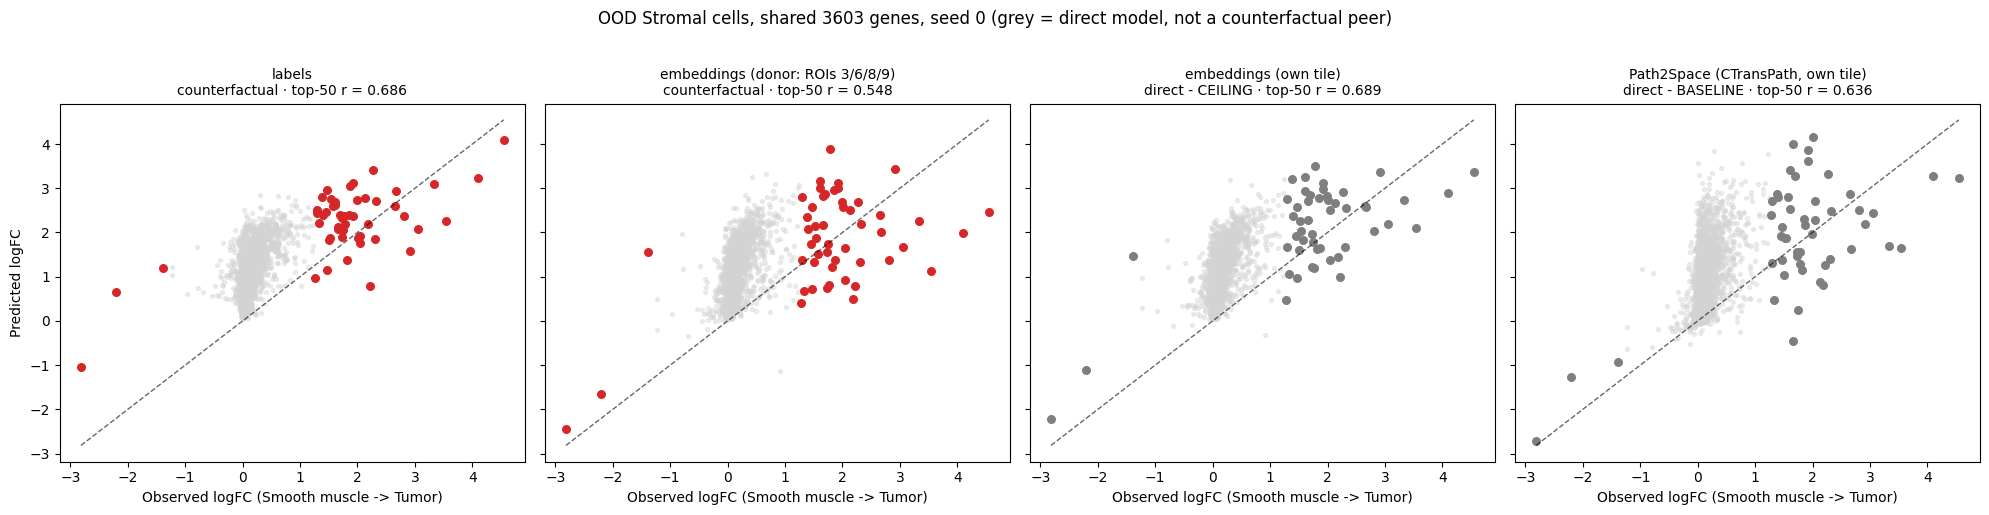

In [12]:
import matplotlib.pyplot as plt

PANELS = ["labels", "emb_unseen_ROIs", "emb_ceiling", "path2space"]
ood = lambda a: a[(a.obs[LABELS_KEY].astype(str) == HOLDOUT_CT).values].copy()
obs_g = observed[:, SHARED_GENES]

fig, axes = plt.subplots(1, len(PANELS), figsize=(5 * len(PANELS), 5), sharex=True, sharey=True)
for ax, key in zip(axes, PANELS):
    display, kind, seeds = MODELS[key]
    pred = load_pred(key, None if seeds is None else 0)[:, SHARED_GENES]
    obs_eff, pred_eff = get_perturbation_effects(
        ood(obs_g), ood(pred), pert_col=PERT_COL, control_label=CONTROL_LABEL,
        mode="logfc", predicted_logfc_baseline="observed_control",
    )
    o = obs_eff.loc[HOLDOUT_LABEL].values
    p = pred_eff.loc[HOLDOUT_LABEL].values
    deg = np.argsort(-np.abs(o))[:50]
    r = np.corrcoef(o[deg], p[deg])[0, 1]

    ax.scatter(o, p, s=8, color="lightgray", alpha=0.4)
    ax.scatter(o[deg], p[deg], s=30, color="#d62728" if kind.startswith("counter") else "#7f7f7f")
    lims = [min(o.min(), p.min()), max(o.max(), p.max())]
    ax.plot(lims, lims, "k--", lw=1, alpha=0.6)
    ax.set_xlabel(f"Observed logFC ({CONTROL_LABEL} -> {HOLDOUT_LABEL})")
    ax.set_title(f"{display}\n{kind} · top-50 r = {r:.3f}", fontsize=10)
axes[0].set_ylabel("Predicted logFC")
fig.suptitle(f"OOD {HOLDOUT_CT} cells, shared {len(SHARED_GENES)} genes, seed 0 "
             "(grey = direct model, not a counterfactual peer)", y=1.02)
plt.tight_layout()
plt.show()

nije bas dobro da su svi ovi NOT TOP 50 genes zapravo ful lose predvideni, uglavnom su overestimated u odnosu na observed


## D. Path2Space sanity check — paper-native metric (*not* a model comparison)

**Purpose:** decide whether a weak Path2Space row in C2 means *Path2Space is weak on this slide* or
*our pipeline is broken*. So Path2Space is scored here the way its authors score it, not the way
this benchmark scores models.

Paper's protocol (Methods, "Model evaluation" + "Spatial smoothing"): per-gene **Pearson** between
predicted and measured expression **across locations within a slide**, both sides smoothed by
averaging each location with its neighbours; averaged over slides; a gene counts as robustly
predicted at **r > 0.4** (43% of genes in their TNBC cross-validation, median r = 0.37; 0.35 on
external cohorts).

How that is transferred here:

- **Locations = cells**, the 2,244 scored Tumor cells in ROIs 3/6/8/9; **"slide" = ROI** —
  Pearson is computed within each ROI, then averaged over the four ROIs (the paper averages over
  slides). OOD / ID restrict *which cells* enter the correlation (560 Stromal / 1,684 other).
- **Scale:** measured = `log10(raw count + 1)`, the exact transform Path2Space was trained on;
  predicted = its native output. Pearson is invariant to the per-gene offset/scale, which is the
  point of this metric.
- **Smoothing radius — deviates from the paper, on purpose.** The paper's 200 um radius is
  "one ring of Visium spots" (~8 neighbours). The scored ROIs are only ~300 x 300 um, so 200 um would
  average each cell with ~450 of the ROI's ~550 cells and flatten every gene to the ROI mean. We use
  **56 um = half the 112 um tile width**: measured expression is averaged over roughly the area
  Path2Space actually sees. Neighbours are all cells of the same ROI (any domain / type), and the
  same kernel is applied to prediction and measurement. `SMOOTH_RADIUS_UM` is a single constant.
- Reported **unsmoothed** and **smoothed**, on all 3,603 shared genes and on the C2 OOD top-50.

`embeddings (own tile)` seed 0 is shown on the same footing **as a reference line only** — it was
trained on this slide, so it is not a fair opponent for a zero-shot model on this metric.

In [13]:
from scipy.spatial import cKDTree
import scipy.sparse as sp

SMOOTH_RADIUS_UM = 56.0   # half the 112 um tile; see markdown for why not the paper's 200 um
ROBUST_R = 0.4            # paper's "robustly predicted" threshold

# These come from section A (same kernel): adata, mask_target, SHARED_GENES, p2s_log10.
gcols = adata.var_names.get_indexer(SHARED_GENES)
meas_counts = adata.layers["counts"][:, gcols]
meas_counts = meas_counts.toarray() if sp.issparse(meas_counts) else np.asarray(meas_counts)
meas_log10 = np.log10(meas_counts.astype(np.float32) + 1.0)

# Reference line: embeddings own-tile ceiling, seed 0 (decoder rates on the target cells).
ceil = read_h5ad_compat(os.path.join(PRED_DIR, "emb_ceiling_seed0.h5ad"))[:, SHARED_GENES]
ceil_target = ceil[(ceil.obs[PERT_COL] == HOLDOUT_LABEL).values].X
ceil_target = ceil_target.toarray() if sp.issparse(ceil_target) else np.asarray(ceil_target)
ceil_log10 = np.full_like(meas_log10, np.nan)
ceil_log10[mask_target] = np.log10(ceil_target + 1.0)   # rows are in adata order (make_comparison_adata keeps it)

roi = adata.obs["roi_id"].to_numpy()
xy = np.asarray(adata.obsm["spatial"])
ct = adata.obs[LABELS_KEY].astype(str).to_numpy()


def smooth_within_roi(X, roi_cells, radius):
    """Mean of each cell with all same-ROI cells within `radius` um (paper's KDTree smoothing)."""
    out = X.copy()
    tree = cKDTree(xy[roi_cells])
    for i, nb in zip(roi_cells, tree.query_ball_point(xy[roi_cells], radius)):
        out[i] = X[roi_cells[nb]].mean(axis=0)
    return out


def per_gene_pearson(A, B):
    A = A - A.mean(0); B = B - B.mean(0)
    den = np.sqrt((A ** 2).sum(0) * (B ** 2).sum(0))
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(den > 0, (A * B).sum(0) / den, np.nan)


# Smooth once per ROI, using ALL cells of the ROI as neighbours; ceiling rows outside the target
# are NaN, so the ceiling is smoothed over target cells only (it has no prediction elsewhere).
sources = {"Path2Space": p2s_log10, "embeddings (own tile), seed 0 — reference": ceil_log10}
smoothed = {"measured": meas_log10.copy(), **{k: v.copy() for k, v in sources.items()}}
for r_id in HOLDOUT_ROIS:
    in_roi = np.where(roi == r_id)[0]
    in_roi_t = in_roi[mask_target[in_roi]]
    smoothed["measured"] = smooth_within_roi(smoothed["measured"], in_roi, SMOOTH_RADIUS_UM)
    smoothed["Path2Space"] = smooth_within_roi(smoothed["Path2Space"], in_roi, SMOOTH_RADIUS_UM)
    k = "embeddings (own tile), seed 0 — reference"
    smoothed[k] = smooth_within_roi(smoothed[k], in_roi_t, SMOOTH_RADIUS_UM)

# C2's OOD top-50 (same definition as compare_adatas: |observed logFC| on log1p-CPM).
obs_g = observed[:, SHARED_GENES]
o_eff, _ = get_perturbation_effects(ood(obs_g), ood(obs_g), pert_col=PERT_COL,
                                    control_label=CONTROL_LABEL, mode="logfc")
top50 = np.argsort(-np.abs(o_eff.loc[HOLDOUT_LABEL].values))[:50]

REGIME_CELLS = {"OOD": ct == HOLDOUT_CT, "ID": ct != HOLDOUT_CT}
rows, per_gene = [], {}
for smooth in ["unsmoothed", f"smoothed {SMOOTH_RADIUS_UM:g} um"]:
    meas = meas_log10 if smooth == "unsmoothed" else smoothed["measured"]
    for model, pred_raw in sources.items():
        pred = pred_raw if smooth == "unsmoothed" else smoothed[model]
        for regime, rmask in REGIME_CELLS.items():
            r_per_roi = []
            for r_id in HOLDOUT_ROIS:
                cells_ = np.where((roi == r_id) & mask_target & rmask)[0]
                r_per_roi.append(per_gene_pearson(meas[cells_], pred[cells_]))
            r_gene = np.nanmean(np.vstack(r_per_roi), axis=0)   # paper: average over slides (= ROIs)
            per_gene[(smooth, model, regime)] = r_gene
            for gene_set, idx in [("all 3,603", slice(None)), ("OOD top-50", top50)]:
                rg = r_gene[idx]
                rows.append({"smoothing": smooth, "model": model, "regime": regime,
                             "genes": gene_set, "median_r": np.nanmedian(rg),
                             "mean_r": np.nanmean(rg),
                             f"n_r>{ROBUST_R}": int(np.nansum(rg > ROBUST_R)),
                             "n_genes": int(np.isfinite(rg).sum())})

table_d = pd.DataFrame(rows).set_index(["smoothing", "genes", "regime", "model"]).sort_index()
table_d.to_csv(os.path.join(PRED_DIR, "path2space_sanity_paper_metric.csv"))
pd.DataFrame({" | ".join(k): v for k, v in per_gene.items()}, index=SHARED_GENES).to_csv(
    os.path.join(PRED_DIR, "path2space_sanity_per_gene_r.csv"))

print("TABLE D — PATH2SPACE SANITY CHECK (paper-native per-gene Pearson; NOT a model comparison)")
print(f"paper reference: median r = 0.37 (TNBC CV) / 0.35 (external), robust = r > {ROBUST_R}")
table_d.round(3)

/tmp/ipykernel_625461/4105565297.py:70: RuntimeWarning: Mean of empty slice
  r_gene = np.nanmean(np.vstack(r_per_roi), axis=0)   # paper: average over slides (= ROIs)


TABLE D — PATH2SPACE SANITY CHECK (paper-native per-gene Pearson; NOT a model comparison)
paper reference: median r = 0.37 (TNBC CV) / 0.35 (external), robust = r > 0.4


median_r  \
smoothing      genes      regime model                                                 
smoothed 56 um OOD top-50 ID     Path2Space                                    0.242   
                                 embeddings (own tile), seed 0 — reference     0.720   
                          OOD    Path2Space                                    0.060   
                                 embeddings (own tile), seed 0 — reference     0.577   
               all 3,603  ID     Path2Space                                   -0.058   
                                 embeddings (own tile), seed 0 — reference     0.330   
                          OOD    Path2Space                                   -0.018   
                                 embeddings (own tile), seed 0 — reference     0.287   
unsmoothed     OOD top-50 ID     Path2Space                                    0.026   
                                 embeddings (own tile), seed 0 — reference     0.330   
                          OOD    Path2Space                                   -0.041   
                                 embeddings (own tile), seed 0 — reference     0.404   
               all 3,603  ID     Path2Space                                   -0.006   
                                 embeddings (own tile), seed 0 — reference     0.145   
                          OOD    Path2Space                                   -0.017   
                                 embeddings (own tile), seed 0 — reference     0.110   

                                                                            mean_r  \
smoothing      genes      regime model                                               
smoothed 56 um OOD top-50 ID     Path2Space                                  0.189   
                                 embeddings (own tile), seed 0 — reference   0.682   
                          OOD    Path2Space                                  0.054   
                                 embeddings (own tile), seed 0 — reference   0.537   
               all 3,603  ID     Path2Space                                 -0.050   
                                 embeddings (own tile), seed 0 — reference   0.333   
                          OOD    Path2Space                                 -0.017   
                                 embeddings (own tile), seed 0 — reference   0.288   
unsmoothed     OOD top-50 ID     Path2Space                                  0.024   
                                 embeddings (own tile), seed 0 — reference   0.363   
                          OOD    Path2Space                                 -0.035   
                                 embeddings (own tile), seed 0 — reference   0.393   
               all 3,603  ID     Path2Space                                 -0.005   
                                 embeddings (own tile), seed 0 — reference   0.161   
                          OOD    Path2Space                                 -0.014   
                                 embeddings (own tile), seed 0 — reference   0.120   

                                                                            n_r>0.4  \
smoothing      genes      regime model                                                
smoothed 56 um OOD top-50 ID     Path2Space                                      15   
                                 embeddings (own tile), seed 0 — reference       46   
                          OOD    Path2Space                                       1   
                                 embeddings (own tile), seed 0 — reference       40   
               all 3,603  ID     Path2Space                                      63   
                                 embeddings (own tile), seed 0 — reference     1428   
                          OOD    Path2Space                                      32   
                                 embeddings (own tile), seed 0 — reference     1193   
unsmoothed     OOD top-50 ID     Path2Space                             

ID and OOD for path2space are invaraiant which is supposed to be like that, bcs this entire thing is OOD prediction for path2space. smoothing over 56 um is definetly better but it still underperforms big

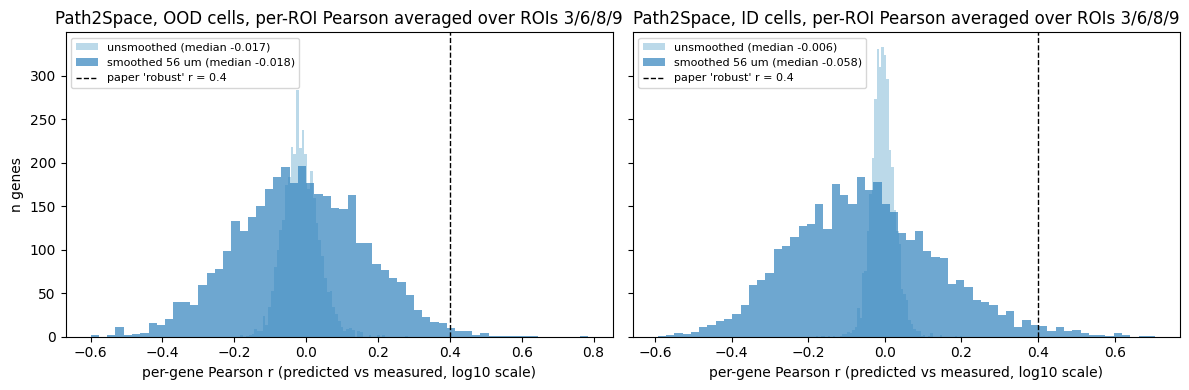

In [14]:
# Distribution of per-gene r for Path2Space, all shared genes, both regimes, before/after smoothing.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, regime in zip(axes, ["OOD", "ID"]):
    for smooth, color in [("unsmoothed", "#9ecae1"), (f"smoothed {SMOOTH_RADIUS_UM:g} um", "#3182bd")]:
        r = per_gene[(smooth, "Path2Space", regime)]
        r = r[np.isfinite(r)]
        ax.hist(r, bins=60, alpha=0.7, color=color, label=f"{smooth} (median {np.median(r):.3f})")
    ax.axvline(ROBUST_R, color="k", ls="--", lw=1, label=f"paper 'robust' r = {ROBUST_R}")
    ax.set_title(f"Path2Space, {regime} cells, per-ROI Pearson averaged over ROIs 3/6/8/9")
    ax.set_xlabel("per-gene Pearson r (predicted vs measured, log10 scale)")
    ax.legend(fontsize=8)
axes[0].set_ylabel("n genes")
plt.tight_layout()
plt.show()

### Where does Path2Space's signal live — between tissues or within them?

`gene_expression_prediction.ipynb` reported per-gene Spearman up to 0.55 (EEF1G) — but pooled over
**all 36 ROIs**, where most variance is *between* tissue types. Table D correlates *within* each
Tumor ROI. The cell below computes the same per-gene Pearson three ways on the native log10 scale
(unsmoothed): pooled over all 14,170 LOO cells, on the 36 ROI means, and within ROIs 3/6/8/9 (as in
Table D). If pooled / ROI-mean r is high while within-ROI r is ~0, Path2Space is working as a
**tissue-type** readout and carries no within-tumour, cell-to-cell signal on this slide.

In [15]:
all_cells = np.arange(adata.n_obs)
r_pooled = per_gene_pearson(meas_log10, p2s_log10)

roi_ids = np.unique(roi)
roi_mean = lambda X: np.vstack([X[roi == r].mean(0) for r in roi_ids])
r_roimean = per_gene_pearson(roi_mean(meas_log10), roi_mean(p2s_log10))

r_within = np.nanmean(np.vstack([
    per_gene_pearson(meas_log10[(roi == r) & mask_target], p2s_log10[(roi == r) & mask_target])
    for r in HOLDOUT_ROIS]), axis=0)

where = pd.DataFrame({
    "median_r": [np.nanmedian(x) for x in (r_pooled, r_roimean, r_within)],
    f"n_r>{ROBUST_R}": [int(np.nansum(x > ROBUST_R)) for x in (r_pooled, r_roimean, r_within)],
}, index=pd.Index([f"pooled, all {adata.n_obs} cells / {len(roi_ids)} ROIs",
                   f"ROI means ({len(roi_ids)} points)",
                   "within ROIs 3/6/8/9 (Table D, unsmoothed)"], name="Path2Space, 3,603 genes"))
print("PATH2SPACE — BETWEEN-TISSUE vs WITHIN-TISSUE SIGNAL")
where.round(3)

PATH2SPACE — BETWEEN-TISSUE vs WITHIN-TISSUE SIGNAL


/tmp/ipykernel_625461/552194077.py:8: RuntimeWarning: Mean of empty slice
  r_within = np.nanmean(np.vstack([


,median_r,n_r>0.4
"Path2Space, 3,603 genes",,
"pooled, all 14170 cells / 36 ROIs",0.051,6
ROI means (36 points),0.556,2329
"within ROIs 3/6/8/9 (Table D, unsmoothed)",-0.005,0
